# Una CNN compacta para reconocer dígitos desplazados

¿Qué necesita una CNN para reconocer un dígito después de promediar sus mapas de activación? Entrenamos siete variantes con Global Average Pooling (GAP). El criterio de selección es superar el 95 % de exactitud en validación en la época 20 y, entre las variantes que lo logren con menos de 54 330 parámetros entrenables, elegir la de menor tamaño. La prueba se usa una sola vez, después de fijar la arquitectura.

La ejecución guardada en `icd-21-cnn.ipynb` sirve como referencia histórica. A continuación se reproducen sus cifras. Las tablas de resultados del experimento se calculan nuevamente.

| Modelo de referencia | Parámetros entrenables | Validación | Prueba a 0 px | Prueba a 4 px |
|---|---:|---:|---:|---:|
| CNN + Flatten | 54 330 | 96.87 % | 97.15 % | 37.21 % |
| CNN + GAP | 2 650 | 44.07 % | 46.35 % | 46.38 % |

## Datos y protocolo

Se conservan las particiones estratificadas de MNIST del notebook de clase y la semilla 42. Cada imagen de 28 × 28 recibe cuatro píxeles negros por lado. Todos los modelos ven el mismo conjunto y orden de lotes, sin aumentación. Se entrena con Adam a 0.001, entropía cruzada categórica dispersa y lotes de 128 durante 20 épocas completas. Se toma la última época para todos los resultados.

In [1]:
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from tensorflow import keras

print(f"Python {platform.python_version()} · TensorFlow {tf.__version__} · Keras {keras.__version__}")
print(f"NumPy {np.__version__} · scikit-learn {sklearn.__version__}")

Python 3.12.10 · TensorFlow 2.20.0 · Keras 3.15.1
NumPy 2.5.4 · scikit-learn 1.9.1


In [2]:
SEMILLA = 42
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()
i_ent, i_val = train_test_split(
    np.arange(len(y_des)), train_size=N_ENT, test_size=N_VAL,
    stratify=y_des, random_state=SEMILLA,
)
i_prueba, _ = train_test_split(
    np.arange(len(y_test)), train_size=N_PRUEBA, stratify=y_test,
    random_state=SEMILLA,
)

def preparar_imagenes(imagenes):
    imagenes = np.pad(imagenes, ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0

X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
FORMA = X_ent.shape[1:]
assert not np.intersect1d(i_ent, i_val).size
assert (len(i_ent), len(i_val), len(i_prueba)) == (8000, 1500, 2000)
assert FORMA == (36, 36, 1)
print(f"{len(i_ent):,} de entrenamiento · {len(i_val):,} de validación · {len(i_prueba):,} reservadas para prueba")
print(f"Forma de entrada: {FORMA}")

8,000 de entrenamiento · 1,500 de validación · 2,000 reservadas para prueba
Forma de entrada: (36, 36, 1)


## Arquitecturas

Las bases comparten dos convoluciones de 16 filtros y un max pooling al final. Flatten conserva una característica por posición y canal. GAP reemplaza cada mapa por su promedio espacial, de modo que las convoluciones previas deben producir activaciones informativas sobre la identidad del dígito. [Definición de GAP en Keras](https://keras.io/api/layers/pooling_layers/global_average_pooling2d/)

Cada fila se lee de izquierda a derecha. Los números en **Filtros** indican las convoluciones sucesivas. **Pool tras** marca los números de las convoluciones seguidas de max pooling 2 × 2 con paso 2. Todas las convoluciones son 3 × 3, con paso 1, padding `same`, sesgo y ReLU. Cuando se indica BN, se aplica normalización por lotes entre la convolución y ReLU. Todas las cabezas terminan en una capa densa de 10 salidas con softmax.

A → B añade una cuarta convolución. B → C añade un pooling tras la tercera convolución. C → D introduce BN. D, E, F y G comparten profundidad y ubicación del pooling y varían el número de filtros.

In [3]:
# (filtros por convolución, índices con pooling, normalización por lotes, cabeza)
arquitecturas = {
    "Flatten base": ((16, 16),         (2,),     False, "Flatten"),
    "GAP base":     ((16, 16),         (2,),     False, "GAP"),
    "A":            ((8, 12, 16),      (1, 2),   False, "GAP"),
    "B":            ((8, 12, 16, 24),  (1, 2),   False, "GAP"),
    "C":            ((8, 12, 16, 24),  (1, 2, 3), False, "GAP"),
    "D":            ((8, 12, 16, 24),  (1, 2, 3), True,  "GAP"),
    "E":            ((4, 6, 8, 12),    (1, 2, 3), True,  "GAP"),
    "F":            ((6, 8, 12, 16),   (1, 2, 3), True,  "GAP"),
    "G":            ((12, 16, 24, 32), (1, 2, 3), True,  "GAP"),
}
variantes = [nombre for nombre in arquitecturas if nombre not in ("Flatten base", "GAP base")]
descripcion = pd.DataFrame([
    {"Modelo": nombre, "Filtros": " → ".join(map(str, filtros)),
     "Pool tras": ", ".join(map(str, pools)), "BN": "Sí" if bn else "No", "Cabeza": cabeza}
    for nombre, (filtros, pools, bn, cabeza) in arquitecturas.items()
]).set_index("Modelo")
display(descripcion)

,Filtros,Pool tras,BN,Cabeza
Modelo,,,,
Flatten base,16 → 16,2,No,Flatten
GAP base,16 → 16,2,No,GAP
A,8 → 12 → 16,"1, 2",No,GAP
B,8 → 12 → 16 → 24,"1, 2",No,GAP
C,8 → 12 → 16 → 24,"1, 2, 3",No,GAP
D,8 → 12 → 16 → 24,"1, 2, 3",Sí,GAP
E,4 → 6 → 8 → 12,"1, 2, 3",Sí,GAP
F,6 → 8 → 12 → 16,"1, 2, 3",Sí,GAP
G,12 → 16 → 24 → 32,"1, 2, 3",Sí,GAP


In [4]:
def crear_modelo(nombre):
    filtros, pools, con_bn, cabeza = arquitecturas[nombre]
    capas = [keras.Input(shape=FORMA)]
    for i, canales in enumerate(filtros, start=1):
        capas.append(keras.layers.Conv2D(
            canales, 3, padding="same", activation=None if con_bn else "relu", name=f"conv_{i}"
        ))
        if con_bn:
            capas.extend([keras.layers.BatchNormalization(name=f"bn_{i}"),
                          keras.layers.ReLU(name=f"relu_{i}")])
        if i in pools:
            capas.append(keras.layers.MaxPooling2D(2, name=f"pool_{i}"))
    vector = keras.layers.Flatten if cabeza == "Flatten" else keras.layers.GlobalAveragePooling2D
    capas.extend([vector(name="vector"), keras.layers.Dense(10, activation="softmax", name="salida")])
    return keras.Sequential(capas)


LOTE = 128
EPOCAS = 20
TASA = 0.001

def lotes(X, y=None, mezclar=False):
    datos = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        datos = datos.shuffle(len(X), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)

def entrenar(nombre):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEMILLA)
    modelo = crear_modelo(nombre)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    historia = modelo.fit(
        lotes(X_ent, y_ent, mezclar=True), validation_data=lotes(X_val, y_val),
        epochs=EPOCAS, verbose=0, shuffle=False,
    ).history
    assert len(historia["val_accuracy"]) == EPOCAS
    n_parametros = sum(int(np.prod(v.shape)) for v in modelo.trainable_weights)
    return modelo.get_weights(), historia["val_accuracy"], n_parametros

## Validación y selección

El conteo suma todos los pesos entrenables, incluidos sesgos, la escala y el desplazamiento de BN y la capa densa. Las medias y varianzas móviles de BN se guardan para inferencia y quedan fuera del conteo.

In [5]:
pesos, curvas_val, parametros = {}, {}, {}
for nombre in arquitecturas:
    pesos[nombre], curvas_val[nombre], parametros[nombre] = entrenar(nombre)
    print(f"{nombre:12s} · época {len(curvas_val[nombre])} · validación {100 * curvas_val[nombre][-1]:.2f} %")
assert parametros["Flatten base"] == 54330 and parametros["GAP base"] == 2650

Flatten base · época 20 · validación 96.80 %


GAP base     · época 20 · validación 44.13 %


A            · época 20 · validación 81.67 %


B            · época 20 · validación 87.73 %


C            · época 20 · validación 93.80 %


D            · época 20 · validación 95.67 %


E            · época 20 · validación 90.27 %


F            · época 20 · validación 95.40 %


G            · época 20 · validación 97.00 %


In [6]:
validacion = pd.DataFrame({
    "Parámetros entrenables": parametros,
    "Validación a 20 épocas (%)": {k: 100 * h[-1] for k, h in curvas_val.items()},
})
validacion.index.name = "Modelo"
candidatas = validacion.loc[variantes]
aptas = candidatas[
    (candidatas["Parámetros entrenables"] < parametros["Flatten base"])
    & (candidatas["Validación a 20 épocas (%)"] > 95)
]
if aptas.empty:
    raise ValueError("Ninguna variante ensayada cumple ambos límites.")
ganador = aptas.sort_values(
    ["Parámetros entrenables", "Validación a 20 épocas (%)"], ascending=[True, False]
).index[0]
def estado(nombre):
    if nombre == ganador:
        return "Seleccionada"
    if nombre in aptas.index:
        return "Cumple"
    return "Referencia" if nombre not in variantes else "Fuera del umbral"

tabla_val = validacion.assign(Selección=[estado(n) for n in validacion.index])
with pd.option_context("display.float_format", "{:.2f}".format):
    display(tabla_val)

,Parámetros entrenables,Validación a 20 épocas (%),Selección
Modelo,,,
Flatten base,54330,96.80,Referencia
GAP base,2650,44.13,Referencia
A,2870,81.67,Fuera del umbral
B,6430,87.73,Fuera del umbral
C,6430,93.80,Fuera del umbral
D,6550,95.67,Cumple
E,1768,90.27,Fuera del umbral
F,3374,95.40,Seleccionada
G,12786,97.00,Cumple


In [7]:
v = validacion["Validación a 20 épocas (%)"]
pares = [("A", "B", "Añadir la cuarta convolución"), ("B", "C", "Añadir el tercer max pooling"),
         ("C", "D", "Añadir normalización por lotes")]
efectos = pd.DataFrame([
    {"Comparación": f"{a} → {b}", "Único cambio": cambio,
     "Δ validación (pp)": v[b] - v[a], "Δ parámetros": parametros[b] - parametros[a]}
    for a, b, cambio in pares
]).set_index("Comparación")
with pd.option_context("display.float_format", "{:+.2f}".format):
    display(efectos)

,Único cambio,Δ validación (pp),Δ parámetros
Comparación,,,
A → B,Añadir la cuarta convolución,+6.07,3560
B → C,Añadir el tercer max pooling,+6.07,0
C → D,Añadir normalización por lotes,+1.87,120


## Prueba con desplazamientos

Con la selección cerrada, recuperamos los pesos de la época 20 de los tres modelos. A 0 px se puntúan las 2 000 imágenes originales una vez. A 2 y 4 px se reutiliza la función `desplazar` de clase, que traslada la imagen y rellena con ceros. A cada distancia se calcula la media de cuatro exactitudes, una por dirección cardinal. La caída se calcula antes del redondeo.

In [8]:
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
modelos = {}
for nombre in ("Flatten base", "GAP base", ganador):
    modelo = crear_modelo(nombre)
    modelo.set_weights(pesos[nombre])
    modelos[nombre] = modelo

,0 px (%),2 px (%),4 px (%),Caída (pp)
Modelo,,,,
Flatten base,97.10,82.79,37.29,59.81
GAP base,46.90,46.90,46.88,0.02
GAP F,95.65,91.05,83.85,11.80


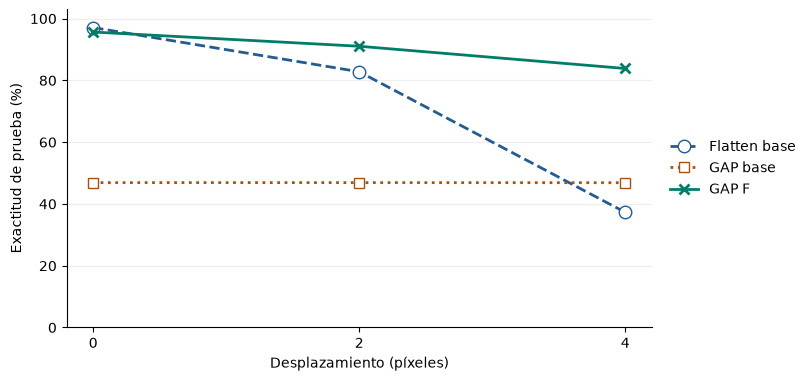

In [9]:
def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado


def predecir(modelo, imagenes):
    return modelo.predict(lotes(imagenes), verbose=0).argmax(axis=1)


seleccionado = "GAP " + ganador
modelos_finales = {
    "Flatten base": modelos["Flatten base"],
    "GAP base": modelos["GAP base"],
    seleccionado: modelos[ganador],
}
distancias = (0, 2, 4)
exactitudes = {
    nombre: [100 * np.mean(predecir(modelo, X_prueba) == y_prueba)]
    for nombre, modelo in modelos_finales.items()
}

for d in distancias[1:]:
    por_direccion = {nombre: [] for nombre in modelos_finales}
    for dy, dx in ((-d, 0), (d, 0), (0, -d), (0, d)):
        imagenes = desplazar(X_prueba, dy, dx)
        for nombre, modelo in modelos_finales.items():
            aciertos = predecir(modelo, imagenes) == y_prueba
            por_direccion[nombre].append(100 * np.mean(aciertos))
    for nombre, valores in por_direccion.items():
        exactitudes[nombre].append(np.mean(valores))

prueba = pd.DataFrame.from_dict(exactitudes, orient="index", columns=[f"{d} px (%)" for d in distancias])
prueba.index.name = "Modelo"
prueba["Caída (pp)"] = prueba["0 px (%)"] - prueba["4 px (%)"]
with pd.option_context("display.float_format", "{:.2f}".format):
    display(prueba)

fig, ax = plt.subplots(figsize=(8.0, 3.7), layout="constrained")
estilos = {
    "Flatten base": dict(color="#245B90", linestyle="--", marker="o", markersize=9, markerfacecolor="white"),
    "GAP base": dict(color="#A95112", linestyle=":", marker="s", markersize=7, markerfacecolor="white"),
    seleccionado: dict(color="#007D69", linestyle="-", marker="x", markersize=7, markeredgewidth=2),
}
for nombre, valores in exactitudes.items():
    ax.plot(distancias, valores, label=nombre, linewidth=2.0, **estilos[nombre])
ax.set(xlabel="Desplazamiento (píxeles)", ylabel="Exactitud de prueba (%)",
       xticks=distancias, yticks=np.arange(0, 101, 20), ylim=(0, 103))
ax.grid(axis="y", alpha=0.22)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.show()

## Conclusión

In [10]:
sel = prueba.loc["GAP " + ganador]
flat, base = prueba.loc["Flatten base"], prueba.loc["GAP base"]
ahorro = parametros["Flatten base"] - parametros[ganador]
ventajas = {d: sel[f"{d} px (%)"] - flat[f"{d} px (%)"] for d in (2, 4)}
primera = next((d for d in (2, 4) if ventajas[d] > 0), None)
comparacion = (f"La ventaja sobre Flatten aparece a **{primera} px** "
               f"({ventajas[primera]:+.2f} pp), la primera distancia desplazada donde lo supera."
               if primera is not None else "Flatten iguala o supera a la variante en ambas distancias.")
cruces = [(a, b, cambio) for a, b, cambio in pares if v[a] <= 95 < v[b]]
if cruces:
    a, b, cambio = cruces[0]
    umbral = (f"**{cambio}** hizo que {b} cruzara el 95 % con un único cambio respecto de {a} "
              f"({v[a]:.2f} % → {v[b]:.2f} %).")
else:
    umbral = "Ninguna comparación de un solo cambio en A → D aisló el cruce del umbral."

display(Markdown(
    f"{umbral} La cuarta convolución ya había mejorado la validación de {v['A']:.2f} % "
    f"a {v['B']:.2f} %, y el tercer pooling la llevó a {v['C']:.2f} %. Con este pooling "
    f"la última convolución combina rasgos sobre un mapa de 4 × 4 en vez de 9 × 9. "
    f"Así puede integrar trazos más distantes antes de que GAP promedie cada canal.\n\n"
    f"**GAP {ganador}** fue la variante más pequeña que cumplió ambos límites. Obtuvo "
    f"**{v[ganador]:.2f} % en validación** con **{parametros[ganador]:,} parámetros entrenables** "
    f"y ahorró **{ahorro:,}** frente a Flatten (**{100 * ahorro / parametros['Flatten base']:.2f} %**).\n\n"
    f"{comparacion} A 4 px, GAP {ganador} conserva **{sel['4 px (%)']:.2f} %** y pierde "
    f"{sel['Caída (pp)']:.2f} pp respecto a 0 px. Flatten conserva **{flat['4 px (%)']:.2f} %** "
    f"y pierde {flat['Caída (pp)']:.2f} pp. El GAP base cambia apenas "
    f"{base['4 px (%)'] - base['0 px (%)']:+.2f} pp y termina con {base['4 px (%)']:.2f} % a 4 px."
))

**Añadir normalización por lotes** hizo que D cruzara el 95 % con un único cambio respecto de C (93.80 % → 95.67 %). La cuarta convolución ya había mejorado la validación de 81.67 % a 87.73 %, y el tercer pooling la llevó a 93.80 %. Con este pooling la última convolución combina rasgos sobre un mapa de 4 × 4 en vez de 9 × 9. Así puede integrar trazos más distantes antes de que GAP promedie cada canal.

**GAP F** fue la variante más pequeña que cumplió ambos límites. Obtuvo **95.40 % en validación** con **3,374 parámetros entrenables** y ahorró **50,956** frente a Flatten (**93.79 %**).

La ventaja sobre Flatten aparece a **2 px** (+8.26 pp), la primera distancia desplazada donde lo supera. A 4 px, GAP F conserva **83.85 %** y pierde 11.80 pp respecto a 0 px. Flatten conserva **37.29 %** y pierde 59.81 pp. El GAP base cambia apenas -0.02 pp y termina con 46.88 % a 4 px.